# Một coin, grid lớn — chiến thuật hiện tại (SHORT phá dải Bollinger + lọc biến động + trailing, không RSI)

Dùng `vol_filter_engine.py` cùng thư mục (numba CPU). Sửa **ô Cấu hình**, rồi **Run All**. Grid mặc định ~49 nghìn bộ: ~30 giây cho một coin 15min.

**Trailing + chốt lời:** khi `trail_r > 0` và `tp_sl_ratio > 0`, lệnh thoát ở cái chạm trước — stop đã kéo hoặc TP; cùng nến chạm cả hai thì tính stop (thận trọng). Nghiên cứu 36 coin (lọc bật, 2022–2025): thêm TP làm R/năm giảm nhẹ (trail 1R: 5.6 → 4.6 với TP 3R, 5.3 với TP 5R; trail 1.5R: 7.2 → 5.8 / 6.7), maxDD gần như không đổi; 2026: trail 1R + TP 3R/5R +1.3 / +1.4 so với +1.2 không TP.

**Luật:** short ở close nến `t` khi `close[t-1] > lower[t] > close[t]` và `vol_ratio[t] < vol_ratio_max` (`vol_ratio` = độ lệch chuẩn log-return `vol_window` nến / trung vị của nó trong `vol_days` ngày; `0` = tắt lọc). Rủi ro R = `sl_multiplier × (upper − entry)`. Thoát: trailing — stop kéo xuống `đáy thấp nhất từ lúc vào + trail_r × R` (`0` = tắt), chốt lời `tp_sl_ratio × R` (`0` = không), timeout `max_holding_bars` nến. Không dùng RSI.

**Grid lớn dễ overfit:** càng nhiều bộ, bộ đứng đầu càng dễ là bộ "may mắn" — walk-forward 24/6 trên 46 coin: top-10 theo score riêng chỉ hơn chọn ngẫu nhiên ~0.4 R/coin mỗi 6 tháng (2.36 vs 1.92). Notebook có:
- `NEIGHBOUR_RANKING`: xếp hạng theo **trung bình score của vùng ±1 nấc** mỗi tham số. Đã kiểm tra trên 46 coin: **không tốt hơn** score riêng với chiến thuật này (2.16 vs 2.36 R/coin mỗi 6 tháng, tốt hơn ở 19/46 coin) → mặc định tắt, giữ để so sánh;
- ô **Theo từng chiều**: trung vị cả grid theo từng tham số và từng cặp — đáng tin hơn bộ đứng đầu;
- ô **Lân cận của bộ được chọn**: đổi từng tham số một nấc xem kết quả thay đổi bao nhiêu.

**Ngày:** train = [`TRAIN_START`, `TEST_START`), test = [`TEST_START`, `TEST_END`]; đặt vào ngày 1 của tháng. Dữ liệu 5m có từ 2021-01; walk-forward cần `WF_FIRST_TEST` ≥ `TRAIN_START` + `WF_TRAIN` tháng.

**Nhớ (nghiên cứu 36–47 coin):** walk-forward ngoài mẫu ≈ +5–6 R/coin/năm 2023–2025, 2026 yếu; coin biến động thấp (BTC, BNB, TRX, LTC…) và CRV thường kém.

In [128]:
# CẤU HÌNH
DATA_CSV = "../data_5m/dogeusdt_futures_5min.csv"
TIMEFRAME = "15min"              # vol_window và max_holding_bars tính theo nến
TRAIN_START = "2022-01-01"
TEST_START = "2026-01-01"
TEST_END = "2026-10-19"
WARMUP_DAYS = 120                # nạp thêm trước TRAIN_START để chỉ báo ấm

SCORE = "perf/maxDD"             # "perf/maxDD" (khuyên dùng), "sharpe" (theo tháng), "perf"
NEIGHBOUR_RANKING = False        # True = xếp hạng theo trung bình score vùng ±1 nấc (kiểm tra 46 coin: không tốt hơn)
TOP_K = 10
MIN_TRADES = 100                 # số lệnh tối thiểu trong train
MIN_TRADES_PER_YEAR = 50         # số lệnh của năm ít lệnh nhất (quy ra cả năm)

SEARCH_SPACE = {                 # 9×5×5×4×3×6×3×3 = 145 800 bộ bật lọc (~75 giây / coin)
    "boll_window": [40, 50, 60, 80, 100, 150, 200, 300, 400],
    "boll_window_dev": [1.5, 1.8, 2.0, 2.2, 2.5],
    "sl_multiplier": [0.5, 0.6, 0.8, 1.0, 1.2],
    "vol_window": [48, 96, 192, 288],          # nến (96 = 1 ngày ở 15min)
    "vol_days": [15, 30, 90],                  # ngày
    "vol_ratio_max": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2],
    "trail_r": [1.0],                # 0 = tắt trailing
    "tp_sl_ratio": [1.1, 1.5, 2.0, 3.0],            # chốt lời × R, dùng cùng trailing (chạm cái nào trước thì thoát); 0 = không chốt lời
    "max_holding_bars": [384],
}
COMPARE_VOL_OFF = True           # thêm nhóm tắt lọc (vol_ratio_max = 0) làm mốc so sánh

WF_TRAIN, WF_TEST = 24, 6        # walk-forward: train / test (tháng)
WF_FIRST_TEST = "2024-01-01"
SAVE_CSV = True                  # lưu bảng kết quả cạnh notebook

In [129]:
# Nạp vol_filter_engine.py cùng thư mục
from pathlib import Path
import importlib.util
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
FOLDER = "short_bollinger+RSI+volfilter"
candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    if parent.name == FOLDER:
        candidates.append(parent / "vol_filter_engine.py")
    candidates.append(parent / "reference" / FOLDER / "vol_filter_engine.py")
engine_path = next((p.resolve() for p in candidates if p.is_file()), None)
if engine_path is None:
    raise FileNotFoundError("Không tìm thấy vol_filter_engine.py")
for name in ("vol_filter_engine", "multi_position_engine"):
    sys.modules.pop(name, None)
spec = importlib.util.spec_from_file_location("vol_filter_engine", engine_path)
vfe = importlib.util.module_from_spec(spec)
sys.modules["vol_filter_engine"] = vfe
spec.loader.exec_module(vfe)
csv_path = (engine_path.parent / DATA_CSV).resolve() if not Path(DATA_CSV).is_absolute() else Path(DATA_CSV)
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
COIN = csv_path.name.split("usdt")[0]
print("Engine:", engine_path)
print("CSV:", csv_path, "| coin:", COIN)

Engine: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+volfilter\vol_filter_engine.py
CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_5m\dogeusdt_futures_5min.csv | coin: doge


In [130]:
# Dữ liệu, grid (bật lọc + nhóm tắt lọc), chạy
load_start = (pd.Timestamp(TRAIN_START) - pd.Timedelta(days=WARMUP_DAYS)).strftime("%Y-%m-%d")
bars = vfe.load_bars(csv_path, TIMEFRAME, load_start, TEST_END)
months = vfe.month_index(bars, pd.Timestamp(TRAIN_START).strftime("%Y-%m"))
month_start = pd.date_range(pd.Timestamp(TRAIN_START).to_period("M").to_timestamp(), periods=months.max() + 1, freq="MS")
ts = bars.timestamp.to_numpy()
train_from = int(np.searchsorted(ts, np.datetime64(pd.Timestamp(TRAIN_START))))
test_from = int(np.searchsorted(ts, np.datetime64(pd.Timestamp(TEST_START))))
n_train_m = int((pd.Timestamp(TEST_START).to_period("M") - pd.Timestamp(TRAIN_START).to_period("M")).n)
if bars.timestamp.iloc[0] > pd.Timestamp(TRAIN_START):
    print(f"Lưu ý: dữ liệu bắt đầu {bars.timestamp.iloc[0].date()}, sau TRAIN_START")

space = {**SEARCH_SPACE, "rsi_window": [5], "rsi_threshold": [100]}
caps = [c for c in space["vol_ratio_max"] if c > 0]
blocks = []                                      # (tên, không gian) — mỗi khối là một tích đầy đủ, dùng cho lân cận
if caps:
    blocks.append(("bật lọc", {**space, "vol_ratio_max": caps}))
if COMPARE_VOL_OFF or len(caps) < len(space["vol_ratio_max"]):
    blocks.append(("tắt lọc", {**space, "vol_window": space["vol_window"][:1], "vol_days": space["vol_days"][:1],
                               "vol_ratio_max": [0]}))
grids = [vfe.parameter_grid(s).assign(khối=name) for name, s in blocks]
grid = pd.concat(grids, ignore_index=True)
print(f"Dữ liệu {len(bars):,} nến: {bars.timestamp.iloc[0]} → {bars.timestamp.iloc[-1]}")
print("Grid:", " + ".join(f"{len(g):,} ({n})" for g, (n, _) in zip(grids, blocks)), f"= {len(grid):,} bộ")
t0 = time.perf_counter()
R, N, stats = vfe.run_grid(vfe.SIDE_SHORT, bars, grid, TIMEFRAME, months, stats_from=train_from, stats_to=test_from)
print(f"Thời gian: {time.perf_counter() - t0:.0f}s")

Dữ liệu 179,808 nến: 2021-09-03 00:00:00 → 2026-10-19 23:45:00
Grid: 64,800 (bật lọc) + 900 (tắt lọc) = 65,700 bộ
Thời gian: 22s


In [131]:
# SCORE trên train (+ xếp hạng lân cận) — chạy lại riêng ô này sau khi đổi SCORE, NEIGHBOUR_RANKING, MIN_TRADES*, TOP_K
train_years = n_train_m / 12
Rm, Nm = R[:, :n_train_m], N[:, :n_train_m]
result = grid.copy()
result["train_R"] = stats.performance
result["train_maxDD"] = stats.max_dd
result["train_trades"] = stats.number_of_trade
result["train_win_rate"] = stats.win_rate
result["train_R_per_year"] = result.train_R / train_years
years = month_start[:n_train_m].year
spans = [(np.flatnonzero(years == y)[0], np.flatnonzero(years == y)[-1] + 1) for y in sorted(set(years))]
long_spans = [s for s in spans if s[1] - s[0] >= 6] or spans
result["min_trades_per_year"] = np.min([Nm[:, a:b].sum(1) * 12 / (b - a) for a, b in long_spans], axis=0)
for y, (a, b) in zip(sorted(set(years)), spans):
    result[f"R_{y}"] = Rm[:, a:b].sum(1)
result["test_R"] = R[:, n_train_m:].sum(1)
result["test_trades"] = N[:, n_train_m:].sum(1)
sd = Rm.std(1, ddof=1)
own = {"perf/maxDD": result.train_R / np.maximum(result.train_maxDD, 1.0), "perf": result.train_R,
       "sharpe": pd.Series(np.where(sd > 0, Rm.mean(1) / np.where(sd > 0, sd, 1), np.nan))}[SCORE].to_numpy()
eligible = ((result.train_trades >= MIN_TRADES) & (result.min_trades_per_year >= MIN_TRADES_PER_YEAR)).to_numpy()
result["score_own"] = np.where(eligible, own, np.nan)


def box_sum(a, shape):
    a = a.reshape(shape)
    for axis, size in enumerate(shape):
        if size > 1:
            p = np.pad(a, [(1, 1) if i == axis else (0, 0) for i in range(a.ndim)])
            a = sum(np.take(p, np.arange(k, k + size), axis=axis) for k in range(3))
    return a.reshape(-1)


def neighbour_mean(values, valid, shape):
    # mean over the +-1-step box in every dimension (itself included), valid sets only; NaN when under half the
    # in-grid neighbours are valid, or the set itself is not
    total = box_sum(np.where(valid, values, 0.0), shape)
    count = box_sum(valid.astype(float), shape)
    inside = box_sum(np.ones(len(values)), shape)
    with np.errstate(all="ignore"):
        m = total / count
    m[(count < inside / 2) | ~valid] = np.nan
    return m


neigh = np.full(len(result), np.nan)
start = 0
for (name, s), g in zip(blocks, grids):
    shape = [len(s[k]) for k in vfe.GRID_COLUMNS]
    sl = slice(start, start + len(g))
    v = result.score_own.to_numpy()[sl]
    neigh[sl] = neighbour_mean(np.nan_to_num(v), np.isfinite(v), shape)
    start += len(g)
result["score_neigh"] = neigh
result["score"] = result.score_neigh if NEIGHBOUR_RANKING else result.score_own
ranked = result[result.score.notna()].sort_values("score", ascending=False)
print(f"Score: {SCORE}{' (trung bình lân cận ±1 nấc)' if NEIGHBOUR_RANKING else ''} | đủ điều kiện "
      f"{int(eligible.sum()):,}/{len(result):,} (≥ {MIN_TRADES} lệnh train, ≥ {MIN_TRADES_PER_YEAR} lệnh/năm)")
params_cols = ["khối", "boll_window", "boll_window_dev", "sl_multiplier", "vol_window", "vol_days", "vol_ratio_max",
               "trail_r", "tp_sl_ratio", "max_holding_bars"]
show = params_cols + ["score", "score_own", "train_R_per_year", "train_maxDD", "train_trades", "train_win_rate"] + \
       [c for c in result if c.startswith("R_")] + ["test_R", "test_trades"]
display(ranked[show].head(40).round(3))

Score: perf/maxDD | đủ điều kiện 45,675/65,700 (≥ 100 lệnh train, ≥ 50 lệnh/năm)


,khối,boll_window,boll_window_dev,sl_multiplier,vol_window,vol_days,vol_ratio_max,trail_r,tp_sl_ratio,max_holding_bars,...,train_R_per_year,train_maxDD,train_trades,train_win_rate,R_2022,R_2023,R_2024,R_2025,test_R,test_trades
4290,bật lọc,40,2.0,1.2,192,30,0.7,1.0,3.0,384,...,17.877,4.109,254,0.469,23.743,23.578,9.298,14.888,-3.190,38
52070,bật lọc,300,1.8,0.5,48,90,0.9,1.0,3.0,384,...,15.092,3.639,217,0.452,25.523,7.085,6.451,21.309,-3.059,42
47189,bật lọc,200,2.0,1.0,96,30,1.2,1.0,3.0,384,...,14.999,3.794,249,0.514,18.987,8.695,11.273,21.042,2.254,57
52059,bật lọc,300,1.8,0.5,48,15,1.0,1.0,3.0,384,...,15.870,4.015,244,0.455,21.305,12.593,12.022,17.559,-8.299,56
25891,bật lọc,80,2.0,1.2,192,30,0.8,1.0,3.0,384,...,17.752,4.600,252,0.476,22.233,10.233,13.360,25.184,-0.000,42
41463,bật lọc,150,2.2,1.0,288,30,1.0,1.0,3.0,384,...,18.088,4.721,239,0.498,22.666,11.304,12.206,26.178,-7.619,50
44075,bật lọc,200,1.5,1.0,48,30,1.2,1.0,1.1,384,...,16.953,4.520,358,0.503,21.267,16.200,15.972,14.373,-0.635,90
52065,bật lọc,300,1.8,0.5,48,30,1.0,1.0,3.0,384,...,16.952,4.598,254,0.445,23.773,13.393,11.043,19.599,-6.741,59
44069,bật lọc,200,1.5,1.0,48,15,1.2,1.0,1.1,384,...,15.891,4.328,361,0.490,24.634,11.688,15.214,12.029,1.258,92
53546,bật lọc,300,2.0,0.5,192,90,0.9,1.0,3.0,384,...,14.373,3.921,212,0.481,23.211,9.150,6.524,18.609,-6.266,34


In [132]:
# Theo từng chiều tham số: TRUNG VỊ các bộ đủ điều kiện (đáng tin hơn bộ đứng đầu)
ok = result[eligible]
on_ok = ok[ok.khối == "bật lọc"]


def family(frame):
    return pd.Series({"số bộ": len(frame), "lệnh train/năm": frame.train_trades.median() / train_years,
                      "train R/năm": frame.train_R_per_year.median(), "% bộ train lãi": (frame.train_R > 0).mean(),
                      "train maxDD": frame.train_maxDD.median(), "test R": frame.test_R.median(),
                      "% bộ test lãi": (frame.test_R > 0).mean()})


cols = ["train_trades", "train_R_per_year", "train_R", "train_maxDD", "test_R"]
print("Bật lọc vs tắt lọc:")
display(ok.groupby("khối")[cols].apply(family).round(2))
for col in ["vol_ratio_max", "vol_window", "vol_days", "boll_window", "boll_window_dev", "sl_multiplier", "trail_r",
            "tp_sl_ratio", "max_holding_bars"]:
    if on_ok[col].nunique() > 1:
        print("Theo", col, "(bật lọc)")
        display(on_ok.groupby(col)[cols].apply(family).round(2))
for a, b in [("boll_window", "boll_window_dev"), ("vol_window", "vol_ratio_max"), ("vol_days", "vol_ratio_max"),
             ("sl_multiplier", "trail_r"), ("trail_r", "tp_sl_ratio")]:
    if on_ok[a].nunique() > 1 and on_ok[b].nunique() > 1:
        for value, label in (("train_R_per_year", "train R/năm"), ("test_R", "test R")):
            print(f"{a} × {b} — {label} (trung vị, bật lọc)")
            display(on_ok.pivot_table(index=a, columns=b, values=value, aggfunc="median").round(2))

Bật lọc vs tắt lọc:


,số bộ,lệnh train/năm,train R/năm,% bộ train lãi,train maxDD,test R,% bộ test lãi
khối,,,,,,,
bật lọc,44815.0,122.75,8.19,0.89,12.64,-5.04,0.22
tắt lọc,860.0,173.62,5.32,0.84,16.38,-2.69,0.32


Theo vol_ratio_max (bật lọc)


,số bộ,lệnh train/năm,train R/năm,% bộ train lãi,train maxDD,test R,% bộ test lãi
vol_ratio_max,,,,,,,
0.7,3788.0,85.50,6.71,0.90,11.20,-7.25,0.17
0.8,6435.0,101.00,8.31,0.91,11.16,-6.65,0.15
0.9,7725.0,120.25,8.76,0.91,11.91,-7.10,0.14
1.0,8541.0,135.75,8.88,0.90,12.59,-4.06,0.26
1.1,9005.0,146.50,8.24,0.89,13.76,-3.42,0.27
1.2,9321.0,153.25,7.48,0.88,14.63,-3.91,0.25


Theo vol_window (bật lọc)


,số bộ,lệnh train/năm,train R/năm,% bộ train lãi,train maxDD,test R,% bộ test lãi
vol_window,,,,,,,
48,11185.0,130.75,7.74,0.85,12.97,-6.81,0.15
96,11436.0,123.00,8.35,0.91,12.68,-4.49,0.24
192,11384.0,119.00,8.04,0.90,12.63,-6.37,0.15
288,10810.0,119.00,8.53,0.92,12.31,-2.58,0.33


... (18 outputs left out)

vol_days × vol_ratio_max — train R/năm (trung vị, bật lọc)


vol_ratio_max,0.7,0.8,0.9,1.0,1.1,1.2
vol_days,,,,,,
15,5.05,7.92,8.53,8.07,7.56,6.74
30,6.22,9.11,9.68,9.63,8.63,7.84
90,8.02,7.95,8.23,8.99,8.65,7.83


vol_days × vol_ratio_max — test R (trung vị, bật lọc)


vol_ratio_max,0.7,0.8,0.9,1.0,1.1,1.2
vol_days,,,,,,
15,-2.69,-4.79,-7.44,-4.44,-3.54,-4.03
30,-5.43,-4.04,-5.70,-3.35,-4.17,-4.35
90,-10.50,-10.73,-7.91,-4.52,-2.65,-3.31


In [133]:
# Ngoài mẫu: top-K theo score trên train, so với chọn ngẫu nhiên (trung vị bộ đủ điều kiện)
if R.shape[1] <= n_train_m:
    print("Không có dữ liệu test")
else:
    rows = []
    for label, mask in [("tất cả", eligible)] + [(n, eligible & (result.khối == n).to_numpy()) for n, _ in blocks]:
        sub = result[mask]
        for how in (["score_neigh", "score_own"] if NEIGHBOUR_RANKING else ["score_own"]):
            top = sub[sub[how].notna()].sort_values(how, ascending=False).head(TOP_K)
            if top.empty:
                continue
            rows.append({"nhóm": label, "xếp theo": "lân cận" if how == "score_neigh" else "riêng", "số bộ": len(sub),
                         f"top-{TOP_K} train R/năm": top.train_R_per_year.mean(), f"top-{TOP_K} test R": top.test_R.mean(),
                         f"top-{TOP_K} % test lãi": (top.test_R > 0).mean(), "top-1 test R": top.test_R.iloc[0],
                         "ngẫu nhiên: test R trung vị": sub.test_R.median(), "ngẫu nhiên: % test lãi": (sub.test_R > 0).mean()})
    print(f"Test {R.shape[1] - n_train_m} tháng ({TEST_START} → {TEST_END})")
    display(pd.DataFrame(rows).round(2))

Test 10 tháng (2026-01-01 → 2026-10-19)


,nhóm,xếp theo,số bộ,top-10 train R/năm,top-10 test R,top-10 % test lãi,top-1 test R,ngẫu nhiên: test R trung vị,ngẫu nhiên: % test lãi
0,tất cả,riêng,45675,16.38,-3.23,0.2,-3.19,-5.00,0.22
1,bật lọc,riêng,44815,16.38,-3.23,0.2,-3.19,-5.04,0.22
2,tắt lọc,riêng,860,13.26,-5.86,0.1,-6.02,-2.69,0.32


,biến thể,R tổng,R/năm,maxDD (tháng),% tháng lãi,R 2024,R 2025,R 2026
0,bật lọc,13.31,4.70,7.86,0.56,2.43,10.00,0.88
1,tắt lọc,16.76,5.91,6.05,0.59,-0.33,15.18,1.90


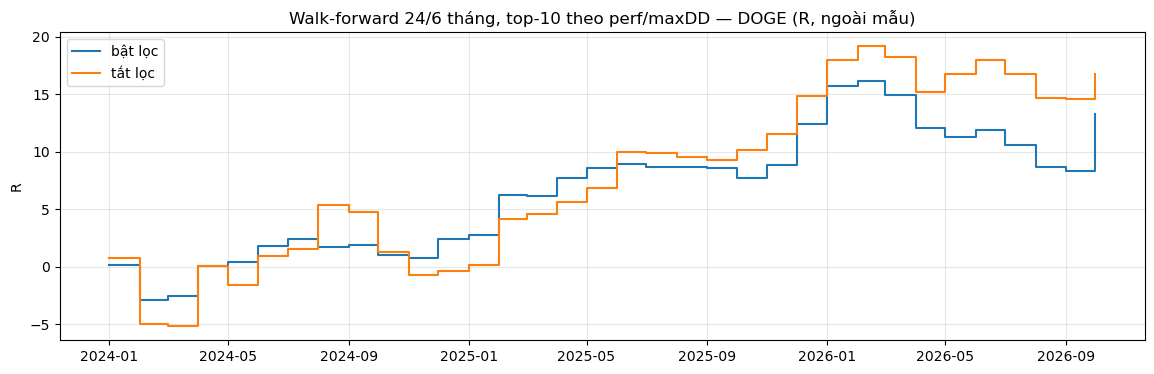

In [134]:
# Walk-forward theo tháng: mỗi WF_TEST tháng chọn lại top-K theo SCORE của WF_TRAIN tháng trước (max DD theo tháng)
first = int((pd.Timestamp(WF_FIRST_TEST).to_period("M") - pd.Timestamp(TRAIN_START).to_period("M")).n)
total_m = R.shape[1]
if first - WF_TRAIN < 0:
    print(f"WF_FIRST_TEST cần ≥ TRAIN_START + {WF_TRAIN} tháng")
else:
    def wf_series(block, neighbour):
        sel = (result.khối == block).to_numpy()
        idx = np.flatnonzero(sel)
        s = dict(blocks)[block]
        shape = [len(s[k]) for k in vfe.GRID_COLUMNS]
        out = np.zeros(total_m - first)
        for m in range(first, total_m, WF_TEST):
            a, b, e = m - WF_TRAIN, m, min(m + WF_TEST, total_m)
            x = R[idx, a:b]
            n = N[idx, a:b].sum(1)
            ok = n >= MIN_TRADES * WF_TRAIN / max(n_train_m, 1)
            sd = x.std(1, ddof=1)
            sc = {"perf/maxDD": x.sum(1) / np.maximum(vfe.monthly_max_dd(x), 1.0), "perf": x.sum(1),
                  "sharpe": np.where(sd > 0, x.mean(1) / np.where(sd > 0, sd, 1), np.nan)}[SCORE]
            sc = np.where(ok & np.isfinite(sc), sc, np.nan)
            if neighbour:
                sc = neighbour_mean(np.nan_to_num(sc), np.isfinite(sc), shape)
            sc = np.nan_to_num(sc, nan=-np.inf)
            if not np.isfinite(sc).any():
                continue
            top = idx[np.argsort(-sc)[:TOP_K]]
            out[m - first:e - first] = R[top, m:e].mean(0)
        return out

    variants = [(n, False) for n, _ in blocks] + ([("bật lọc", True)] if NEIGHBOUR_RANKING and "bật lọc" in dict(blocks) else [])
    curves, rows = {}, []
    for block, nb in variants:
        label = block + (" (lân cận)" if nb else "")
        sres = wf_series(block, nb)
        eq = np.cumsum(sres)
        curves[label] = eq
        ix = pd.Index(month_start[first:total_m])
        rows.append({"biến thể": label, "R tổng": eq[-1], "R/năm": eq[-1] / (len(sres) / 12),
                     "maxDD (tháng)": (np.maximum.accumulate(np.maximum(eq, 0)) - eq).max(), "% tháng lãi": (sres > 0).mean(),
                     **{f"R {y}": v for y, v in pd.Series(sres, index=ix).groupby(ix.year).sum().items()}})
    display(pd.DataFrame(rows).round(2))
    fig, ax = plt.subplots(figsize=(14, 4))
    for label, eq in curves.items():
        ax.step(month_start[first:total_m], eq, where="post", label=label)
    ax.set(title=f"Walk-forward {WF_TRAIN}/{WF_TEST} tháng, top-{TOP_K} theo {SCORE} — {COIN.upper()} (R, ngoài mẫu)", ylabel="R")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

Tham số: {'boll_window': 40, 'boll_window_dev': 2.0, 'sl_multiplier': 1.2, 'tp_sl_ratio': 3.0, 'max_holding_bars': 384, 'vol_window': 192, 'vol_days': 30, 'vol_ratio_max': 0.7, 'trail_r': 1.0} | ID: 4290
Đối chiếu với grid: lệch tối đa theo tháng 0.00e+00


,,lệnh,R,R_mỗi_lệnh,tỷ_lệ_thắng
năm,phần,,,,
2022,train,72,23.743,0.330,0.583
2023,train,70,23.578,0.337,0.457
2024,train,54,9.298,0.172,0.407
2025,train,58,14.888,0.257,0.397
2026,test,38,-3.190,-0.084,0.316


size   mean     sum
phần  outcome                           
test  take_profit       1  2.917   2.917
      trailing_stop    37 -0.165  -6.107
train stop              3 -1.093  -3.279
      take_profit      28  2.927  81.963
      timeout           5  1.063   5.315
      trailing_stop   218 -0.057 -12.492

Tổng 68.3R trên 292 lệnh; maxDD theo lệnh 8.1R; giờ giữ TB 11.6


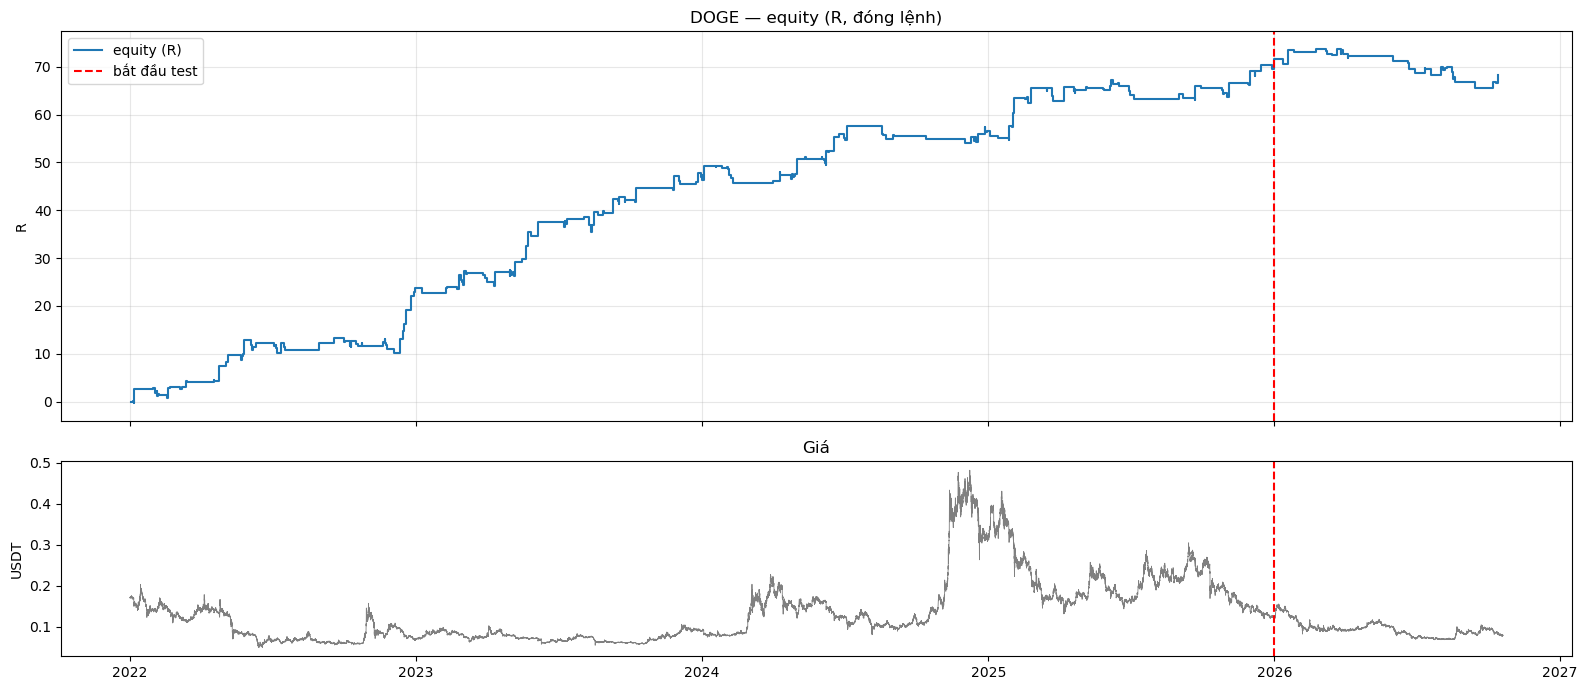

In [135]:
# Backtest một bộ. TRIAL_PARAMS (dict) thắng TRIAL_ID; cả hai None = bộ đứng đầu ranked
TRIAL_ID = None
TRIAL_PARAMS = None   # ví dụ {"boll_window": 200, "boll_window_dev": 2.0, "sl_multiplier": 0.6, "vol_window": 288,
                      #        "vol_days": 90, "vol_ratio_max": 0.9, "trail_r": 1.5, "tp_sl_ratio": 0, "max_holding_bars": 384}
if TRIAL_PARAMS is not None:
    params = {"rsi_window": 5, "rsi_threshold": 100, "trail_r": 0.0, **TRIAL_PARAMS}
    missing = [k for k in vfe.GRID_COLUMNS if k not in params]
    if missing:
        raise ValueError(f"TRIAL_PARAMS thiếu {missing}")
    match = np.all([np.isclose(grid[k].to_numpy(float), float(params[k])) for k in vfe.GRID_COLUMNS], axis=0)
    TRIAL_ID = int(np.flatnonzero(match)[0]) if match.any() else None
else:
    if TRIAL_ID is None:
        TRIAL_ID = int(ranked.index[0])
    params = grid.loc[TRIAL_ID, list(vfe.GRID_COLUMNS)].to_dict()
print("Tham số:", {k: params[k] for k in vfe.GRID_COLUMNS if k not in ("rsi_window", "rsi_threshold")}, "| ID:", TRIAL_ID)
trades = vfe.trace(vfe.SIDE_SHORT, bars, params, TIMEFRAME)
trades = trades[trades.exit_index >= train_from].reset_index(drop=True)
if TRIAL_ID is not None:
    m = months[trades.exit_index.to_numpy()]
    check = np.zeros(R.shape[1])
    np.add.at(check, m[m >= 0], trades.net_r.to_numpy()[m >= 0])
    print(f"Đối chiếu với grid: lệch tối đa theo tháng {np.abs(check - R[TRIAL_ID]).max():.2e}")
trades["phần"] = np.where(trades.exit_index < test_from, "train", "test")
trades["năm"] = pd.to_datetime(trades.exit_timestamp).dt.year
display(trades.groupby(["năm", "phần"]).agg(lệnh=("net_r", "size"), R=("net_r", "sum"), R_mỗi_lệnh=("net_r", "mean"),
                                            tỷ_lệ_thắng=("net_r", lambda s: (s > 0).mean())).round(3))
display(trades.groupby(["phần", "outcome"]).net_r.agg(["size", "mean", "sum"]).round(3))
hours = pd.Timedelta(TIMEFRAME) / pd.Timedelta(hours=1)
eq = trades.set_index(pd.to_datetime(trades.exit_timestamp)).net_r.cumsum()
dd = np.maximum.accumulate(np.maximum(eq, 0)) - eq
print(f"Tổng {eq.iloc[-1]:.1f}R trên {len(trades)} lệnh; maxDD theo lệnh {dd.max():.1f}R; "
      f"giờ giữ TB {trades.holding_bars.mean() * hours:.1f}")
price = bars.set_index("timestamp").close.loc[TRAIN_START:]
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].step(eq.index, eq.to_numpy(), where="post", label="equity (R)")
axes[0].axvline(pd.Timestamp(TEST_START), color="red", ls="--", label="bắt đầu test")
axes[0].set(title=f"{COIN.upper()} — equity (R, đóng lệnh)", ylabel="R")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].plot(price.index, price.to_numpy(), lw=0.6, color="gray")
axes[1].axvline(pd.Timestamp(TEST_START), color="red", ls="--")
axes[1].set(title="Giá", ylabel="USDT")
plt.tight_layout()
plt.show()

In [136]:
# Lân cận của bộ vừa backtest: đổi TỪNG tham số một nấc (±1 trong SEARCH_SPACE). Vùng phẳng = kết quả ít đổi
if TRIAL_ID is None:
    print("Bộ không nằm trong grid")
else:
    base = result.loc[TRIAL_ID]
    s = dict(blocks)[base.khối]
    rows = [{"đổi": "(bộ gốc)", **{k: base[k] for k in ("train_R_per_year", "train_maxDD", "train_trades", "test_R")}}]
    for k in vfe.GRID_COLUMNS:
        values = list(s[k])
        if len(values) < 2:
            continue
        i = int(np.argmin([abs(float(v) - float(base[k])) for v in values]))
        for j in (i - 1, i + 1):
            if 0 <= j < len(values):
                want = {c: base[c] for c in vfe.GRID_COLUMNS}
                want[k] = values[j]
                hit = np.all([np.isclose(result[c].to_numpy(float), float(want[c])) for c in vfe.GRID_COLUMNS], axis=0)
                hit &= (result.khối == base.khối).to_numpy()
                if hit.any():
                    r = result.loc[np.flatnonzero(hit)[0]]
                    rows.append({"đổi": f"{k}: {base[k]:g} → {values[j]:g}",
                                 **{c: r[c] for c in ("train_R_per_year", "train_maxDD", "train_trades", "test_R")}})
    nb = pd.DataFrame(rows)
    display(nb.round(2))
    print(f"Lân cận: train R/năm trung vị {nb.train_R_per_year.iloc[1:].median():.2f} (gốc {base.train_R_per_year:.2f}); "
          f"test R trung vị {nb.test_R.iloc[1:].median():.2f} (gốc {base.test_R:.2f})")

,đổi,train_R_per_year,train_maxDD,train_trades,test_R
0,(bộ gốc),17.88,4.11,254,-3.19
1,boll_window: 40 → 50,10.83,6.29,223,2.33
2,boll_window_dev: 2 → 1.8,13.86,7.50,294,1.25
3,boll_window_dev: 2 → 2.2,16.08,4.46,218,-5.69
4,sl_multiplier: 1.2 → 1,16.44,5.73,291,1.93
5,tp_sl_ratio: 3 → 2,14.11,4.53,261,-1.49
6,vol_window: 192 → 96,9.21,9.67,292,0.11
7,vol_window: 192 → 288,12.76,4.06,220,2.64
8,vol_days: 30 → 15,13.95,5.91,209,-0.02
9,vol_days: 30 → 90,13.63,6.88,291,-8.51


Lân cận: train R/năm trung vị 13.91 (gốc 17.88); test R trung vị 0.48 (gốc -3.19)


In [137]:
# Lưu bảng kết quả
if SAVE_CSV:
    out = engine_path.with_name(f"single_coin_{COIN}_{TIMEFRAME}.csv")
    result.drop(columns=["rsi_window", "rsi_threshold"]).to_csv(out, index=False)
    print("Đã lưu:", out)

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+volfilter\single_coin_doge_15min.csv
